Config

In [1]:
# Pandas
import pandas as pd
pd.set_option("display.max_columns", None)

# Numpy
import numpy as np

In [2]:
DATA_PATH = "UCI_Credit_Card.csv"

In [3]:
SEED = 42
FOLD = 3

In [4]:
df_raw = pd.read_csv(DATA_PATH)
df_raw.shape

(30000, 25)

In [5]:
PAY = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
BILL = [f'BILL_AMT{i}' for i in range(1, 7)]
PAID = [f'PAY_AMT{i}' for i in range(1, 7)]
PROFILE = ['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE']
RAW = PROFILE + PAY + BILL + PAID
TARGET = 'default.payment.next.month'

Trong dataset, có 35 dòng có `ID` khác nhau nhưng các biến đặc trưng và nhãn giống hệt nhau, ta drop các dòng này

In [6]:
df_clean = df_raw.drop_duplicates(subset=RAW + [TARGET], keep="first").copy()
df_clean

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,29996,220000.0,1,3,1,39,0,0,0,0,0,0,188948.0,192815.0,208365.0,88004.0,31237.0,15980.0,8500.0,20000.0,5003.0,3047.0,5000.0,1000.0,0
29996,29997,150000.0,1,3,2,43,-1,-1,-1,-1,0,0,1683.0,1828.0,3502.0,8979.0,5190.0,0.0,1837.0,3526.0,8998.0,129.0,0.0,0.0,0
29997,29998,30000.0,1,2,2,37,4,3,2,-1,0,0,3565.0,3356.0,2758.0,20878.0,20582.0,19357.0,0.0,0.0,22000.0,4200.0,2000.0,3100.0,1
29998,29999,80000.0,1,3,1,41,1,-1,0,0,0,-1,-1645.0,78379.0,76304.0,52774.0,11855.0,48944.0,85900.0,3409.0,1178.0,1926.0,52964.0,1804.0,1


**Cách chia:**
Chia dataset ra thành 3 phần 60/20/20.
+ 60% train: dùng cross-validation 3 fold để chọn mô hình và siêu tham số. Sau khi chọn xong, huấn luyện lại mô hình trên toàn bộ 60% này.
+ 20% validation: dùng để chọn ngưỡng phân loại phù hợp, chẳng hạn ưu tiên phát hiện khách hàng default nhiều hơn.
+ 20% test: dùng để đánh giá cuối cùng sau khi đã chốt mô hình, siêu tham số và ngưỡng. Không dùng kết quả test để điều chỉnh tiếp.

In [7]:
from sklearn.model_selection import train_test_split, StratifiedKFold

X = df_clean[RAW].copy()
y = df_clean[TARGET]


In [8]:
# Chia train , val, test
X_model, X_test, y_model, y_test = train_test_split(X, y, train_size=0.8, test_size=0.2, stratify=y, random_state=SEED, shuffle=True)

X_train, X_val, y_train, y_val = train_test_split(X_model, y_model, train_size=0.75, test_size=0.25, stratify=y_model, random_state=SEED, shuffle=True)

# K FOLD
cv = StratifiedKFold(n_splits=FOLD, random_state=SEED, shuffle=True)

# EDA chỉ dùng tập train
df_train = X_train.join(y_train)


In [9]:
split_summary = pd.DataFrame([
    {"split": name, "rows": len(labels), "share": len(labels) / len(y),
     "default_rate": labels.mean()}
    for name, labels in [("train", y_train), ("validation", y_val), ("test", y_test)]
])

split_summary

,split,rows,share,default_rate
0,train,17979,0.6,0.221258
1,validation,5993,0.2,0.221258
2,test,5993,0.2,0.221258


# EDA

Chỉ phân tích tập train; validation và test được giữ riêng để đánh giá.

In [10]:
df_train.sort_index()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,20000.0,2,2,1,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
3,50000.0,2,2,1,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,50000.0,1,2,1,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0
5,50000.0,1,1,2,37,0,0,0,0,0,0,64400.0,57069.0,57608.0,19394.0,19619.0,20024.0,2500.0,1815.0,657.0,1000.0,1000.0,800.0,0
6,500000.0,1,1,2,29,0,0,0,0,0,0,367965.0,412023.0,445007.0,542653.0,483003.0,473944.0,55000.0,40000.0,38000.0,20239.0,13750.0,13770.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29990,140000.0,1,2,1,41,0,0,0,0,0,0,138325.0,137142.0,139110.0,138262.0,49675.0,46121.0,6000.0,7000.0,4228.0,1505.0,2000.0,2000.0,0
29994,80000.0,1,2,2,34,2,2,2,2,2,2,72557.0,77708.0,79384.0,77519.0,82607.0,81158.0,7000.0,3500.0,0.0,7000.0,0.0,4000.0,1
29995,220000.0,1,3,1,39,0,0,0,0,0,0,188948.0,192815.0,208365.0,88004.0,31237.0,15980.0,8500.0,20000.0,5003.0,3047.0,5000.0,1000.0,0
29997,30000.0,1,2,2,37,4,3,2,-1,0,0,3565.0,3356.0,2758.0,20878.0,20582.0,19357.0,0.0,0.0,22000.0,4200.0,2000.0,3100.0,1


In [11]:
df_train[df_train.duplicated()]

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month


In [12]:
df_train.isnull().sum()

LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default.payment.next.month    0
dtype: int64

In [13]:
# Matplotlib
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (10, 4)

**Phân phối nhãn:**
+ 0: không default. 1: default.
+ Xem số lượng và tỷ lệ của hai lớp.

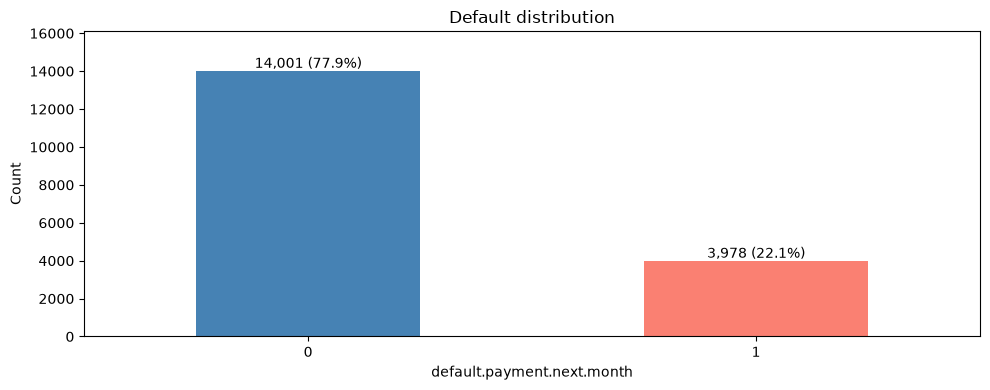

In [14]:
target_count = df_train[TARGET].value_counts().sort_index()
target_rate = target_count / len(df_train) * 100

fig, ax = plt.subplots()
target_count.plot.bar(ax=ax, rot=0, color=['steelblue', 'salmon'])
for i, count in enumerate(target_count):
    ax.text(i, count, f'{count:,} ({target_rate.iloc[i]:.1f}%)', ha='center', va='bottom')
ax.set(xlabel=TARGET, ylabel='Count', title='Default distribution')
ax.set_ylim(0, target_count.max() * 1.15)
plt.tight_layout()     
plt.show()

**Tuổi và hạn mức:**
+ So sánh phân phối theo nhãn default.
+ Dùng density để so sánh hai lớp có số lượng khác nhau.

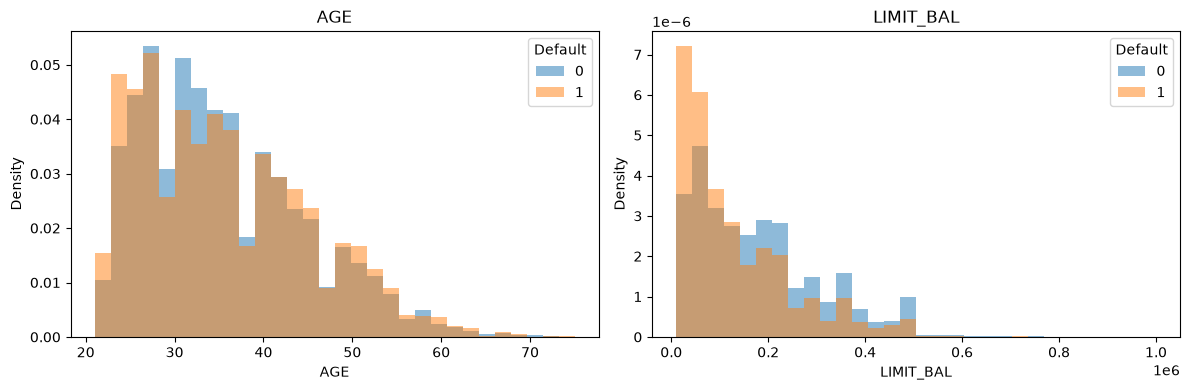

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['AGE', 'LIMIT_BAL']):
    bins = np.histogram_bin_edges(df_train[col], bins=30)
    for label in [0, 1]:
        df_train.loc[df_train[TARGET] == label, col].plot.hist(
            bins=bins, density=True, alpha=0.5, label=str(label), ax=ax
        )
    ax.set(xlabel=col, ylabel='Density', title=col)
    ax.legend(title='Default')
plt.tight_layout()
plt.show()

**Biến phân loại:**
+ Sex: Đa phần khách hàng là nữ
+ Education: Số lượng khách hàng trong tập train chủ yếu là graduate school & university. Có một số lượng ít là đang high school
+ Marriage: Số lượng khách hàng đã cưới và chưa cưới không chênh lệch nhau quá nhiều

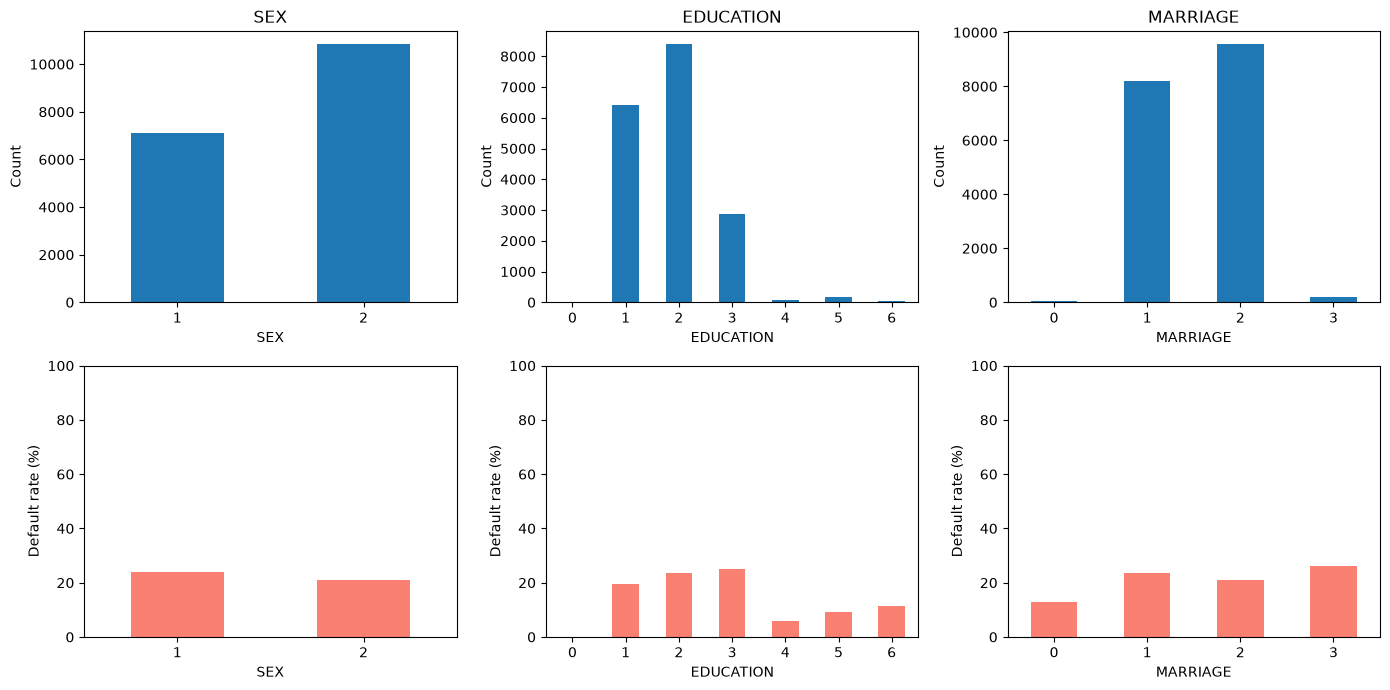

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for i, col in enumerate(['SEX', 'EDUCATION', 'MARRIAGE']):
    df_train[col].value_counts().sort_index().plot.bar(ax=axes[0, i], rot=0)
    (df_train.groupby(col)[TARGET].mean() * 100).plot.bar(ax=axes[1, i], rot=0, color='salmon')
    axes[0, i].set(xlabel=col, ylabel='Count', title=col)
    axes[1, i].set(xlabel=col, ylabel='Default rate (%)', ylim=(0, 100))
plt.tight_layout()
plt.show()

**Trạng thái thanh toán:**
+ Tỷ lệ default theo các mã PAY trong từng tháng.
+ n là số khách hàng của từng mã. Mã PAY > 0 thể hiện trạng thái trễ.
+ Thứ tự PAY_0 đến PAY_6 là gần nhất đến xa nhất.

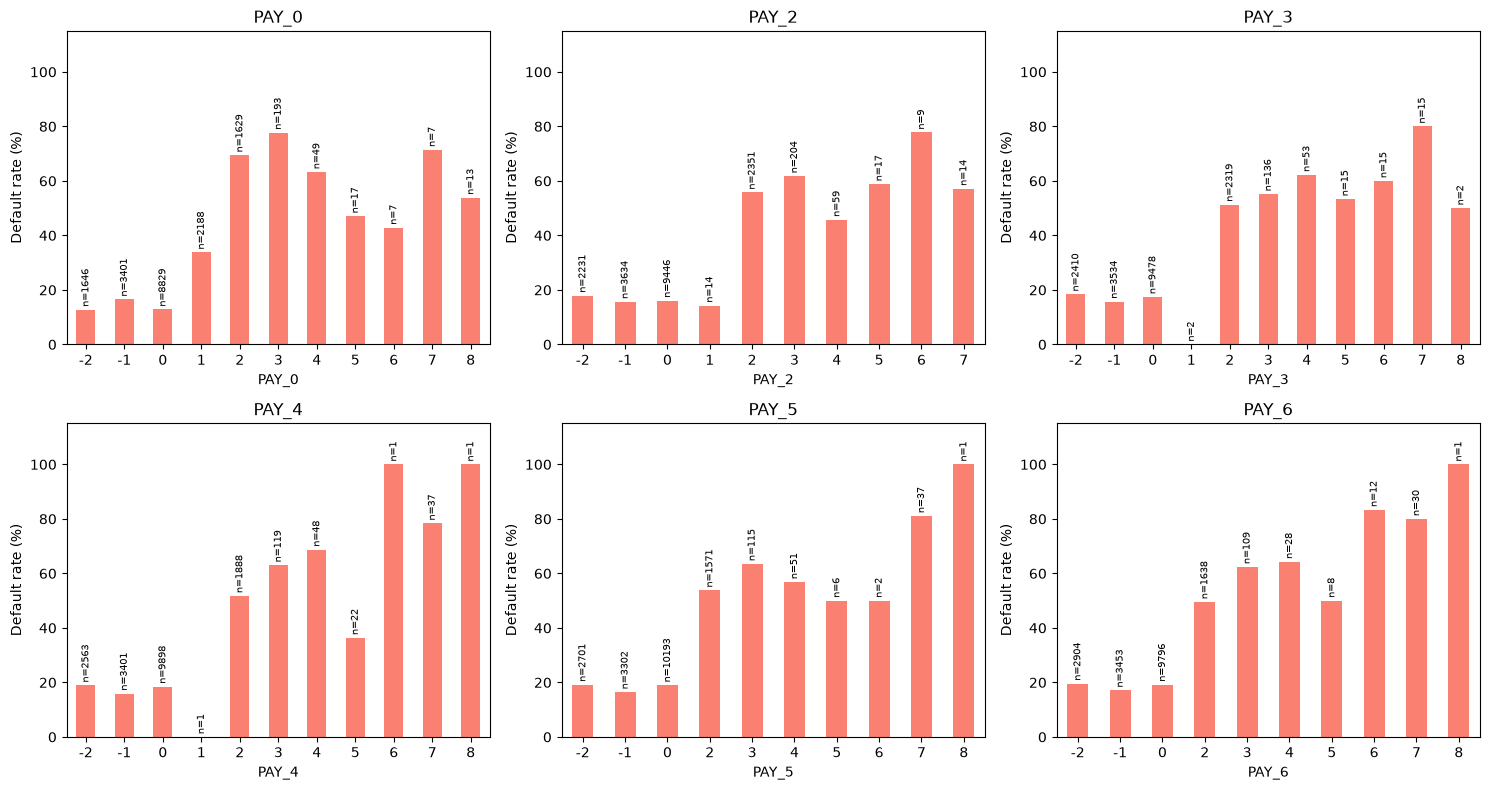

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, PAY):
    pay_summary = df_train.groupby(col)[TARGET].agg(['mean', 'size'])
    (pay_summary['mean'] * 100).plot.bar(ax=ax, rot=0, color='salmon')
    for i, count in enumerate(pay_summary['size']):
        ax.text(i, pay_summary['mean'].iloc[i] * 100 + 1, f'n={count}',
                ha='center', va='bottom', fontsize=7, rotation=90)
    ax.set(xlabel=col, ylabel='Default rate (%)', title=col, ylim=(0, 115))
plt.tight_layout()
plt.show()

**Sao kê và thanh toán:**
+ So sánh median theo nhãn trong sáu tháng.
+ Hiển thị tháng 4 đến tháng 9 theo thứ tự thời gian.
+ Đây là giá trị tổng hợp của hai nhóm, không phải lịch sử của một khách hàng.

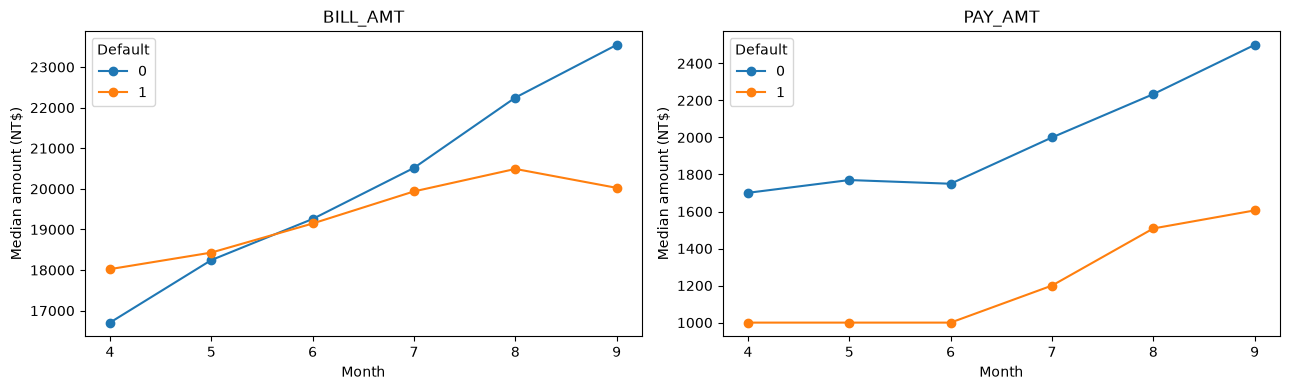

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, cols, title in zip(axes, [BILL, PAID], ['BILL_AMT', 'PAY_AMT']):
    for label in [0, 1]:
        median = df_train.loc[df_train[TARGET] == label, cols[::-1]].median()
        ax.plot([4, 5, 6, 7, 8, 9], median.to_numpy(), marker='o', label=str(label))
    ax.set(xlabel='Month', ylabel='Median amount (NT$)', title=title, xticks=[4, 5, 6, 7, 8, 9])
    ax.legend(title='Default')
plt.tight_layout()
plt.show()

**Tương quan:**
+ Spearman cho các biến số và nhãn default.
+ Tương quan thể hiện liên hệ thống kê, không kết luận quan hệ nhân quả.

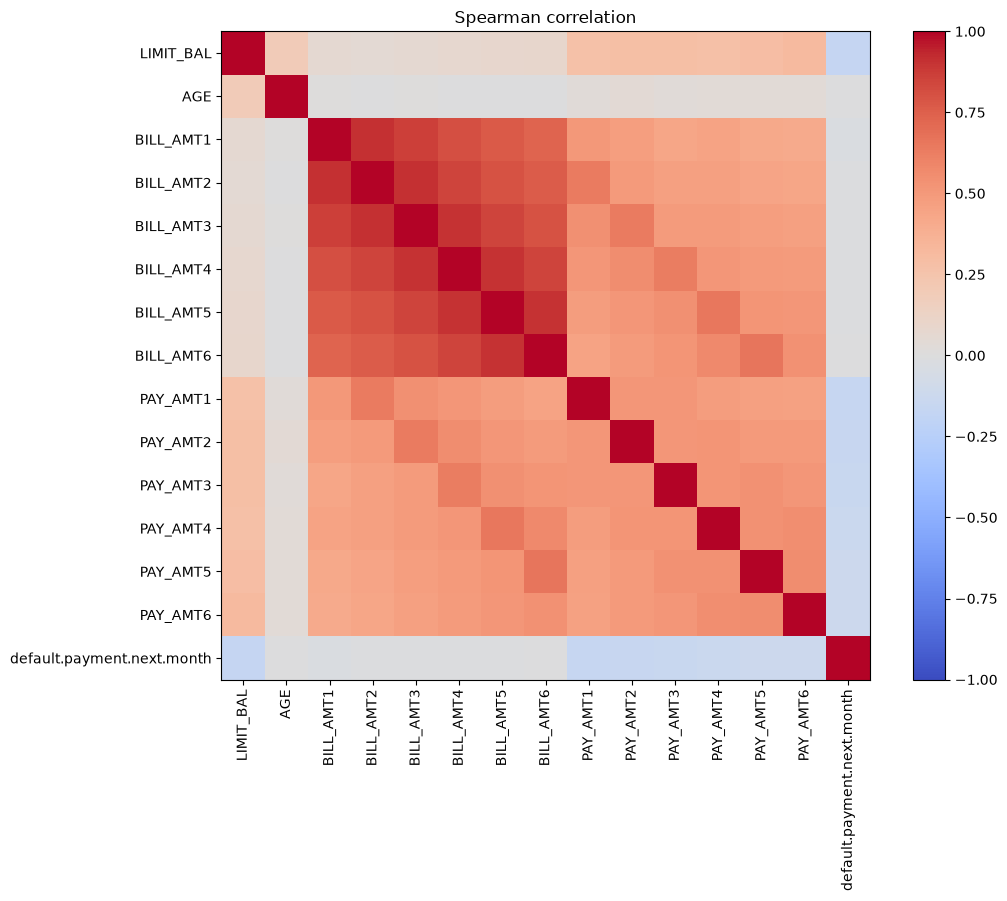

In [19]:
corr_cols = ['LIMIT_BAL', 'AGE'] + BILL + PAID + [TARGET]
corr = df_train[corr_cols].corr(method='spearman')

fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=90)
ax.set_yticks(range(len(corr_cols)), corr_cols)
ax.set_title('Spearman correlation')
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

# FEATURE ENGINEERING

Dựa trên khung phân tích khách hàng RFM (Recency–Frequency–Monetary), được điều chỉnh cho dữ liệu tín dụng, ta xem mỗi dòng là một khách hàng với lịch sử thanh toán và dư nợ trong sáu tháng. Từ lịch sử này, các đặc trưng về thời điểm gần nhất, tần suất và giá trị tiền tệ được xây dựng để dự đoán khả năng khách hàng có hoặc không vỡ nợ thanh toán trong tháng tiếp theo.

In [ ]:
RFM = ["r_months_since_delay", "f_total_delay_months", "m_amt_bill"]

# Tính RFM riêng trên các tập train, val, test
rfm_splits = {
    'train': X_train[RAW].copy(),
    'val': X_val[RAW].copy(),
    'test': X_test[RAW].copy()
}

**Recency:** Mức độ gần đây của hành vi thanh toán/trễ thanh toán
- `r_months_since_delay`: Lần trễ thanh toán gần nhất xảy ra cách đây bao nhiêu tháng.

In [ ]:
for split in rfm_splits.values():
    delay = split[PAY].to_numpy() > 0
    split["r_months_since_delay"] = np.where(delay.any(axis=1), delay.argmax(axis=1), 6)

**Frequency**: Tần suất xuất hiện tình trạng trễ
+ `f_total_delay_months`: Mức độ thường xuyên trễ thanh toán.

In [ ]:
for split in rfm_splits.values():
    split["f_total_delay_months"] = (split[PAY] > 0).sum(axis=1)

**Monetary:** Quy mô thanh toán so với số dư sao kê.
- `m_amt_bill`: Tổng PAY_AMT1..5 / tổng phần dương BILL_AMT2..6, ghép thanh toán với sao kê tháng trước.
- Đây là tỷ lệ tổng hợp qua các kỳ, không phải tỷ lệ tổng nợ đã trả hết. Mẫu số 0 trả NaN; giữ tỷ lệ vượt 1.

In [ ]:
for split in rfm_splits.values():
    sum_bill = split[BILL[1:]].clip(lower=0).sum(axis=1)
    sum_pay = split[PAID[:5]].sum(axis=1)
    split["m_amt_bill"] = sum_pay / sum_bill.where(sum_bill > 0)

In [ ]:
rfm_splits['train'].join(y_train)

**Biểu đồ RFM:**
+ Hàng trên: số khách hàng theo nhóm R, F và M.
+ Hàng dưới: tỷ lệ default của từng nhóm.
+ R = 6 nghĩa là không quan sát thấy tháng trễ trong sáu tháng.
+ M được chia nhóm để vẽ, không thay đổi biến đầu vào của model. NaN là mẫu số bằng 0.

In [ ]:
df_train_rfm = rfm_splits['train'].join(y_train)

m_group = pd.cut(
    df_train_rfm['m_amt_bill'], bins=[-np.inf, 0, 0.25, 0.5, 1, np.inf],
    labels=['0', '(0, 0.25]', '(0.25, 0.5]', '(0.5, 1]', '>1']
).cat.add_categories(['NaN']).fillna('NaN')

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, (name, group) in enumerate([
    ('R', df_train_rfm['r_months_since_delay']),
    ('F', df_train_rfm['f_total_delay_months']),
    ('M', m_group)
]):
    rfm_summary = df_train_rfm.groupby(group, observed=False)[TARGET].agg(['mean', 'size'])
    rfm_summary['size'].plot.bar(ax=axes[0, i], rot=45)
    (rfm_summary['mean'] * 100).plot.bar(ax=axes[1, i], rot=45, color='salmon')
    axes[0, i].set(xlabel=name, ylabel='Count', title=name)
    axes[1, i].set(xlabel=name, ylabel='Default rate (%)', ylim=(0, 100))
plt.tight_layout()
plt.show()

# MODEL

In [ ]:
X_train = rfm_splits['train'].copy()
X_val = rfm_splits['val'].copy()
X_test = rfm_splits['test'].copy()

**Tiền xử lý:**
+ Biến số: điền NaN bằng median. Logistic Regression có thêm RobustScaler.
+ Biến phân loại: điền thiếu bằng mode và dùng OneHotEncoder.
+ Các bước được fit trong từng fold bằng Pipeline.

In [27]:
# SK Learn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# XGBoost
from xgboost import XGBClassifier

# Matplotlib
import matplotlib.pyplot as plt

In [28]:
CAT = ['SEX', 'EDUCATION', 'MARRIAGE'] + PAY
features = {
    'Raw': RAW,
    'Raw + RFM': RAW + RFM
}

In [29]:
def make_pipeline(model, cols, scale=False):
    num_cols = [col for col in cols if col not in CAT]
    num_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale:
        num_steps.append(('scaler', RobustScaler()))

    cat_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])

    preprocess = ColumnTransformer([
        ('num', Pipeline(num_steps), num_cols),
        ('cat', cat_pipeline, CAT)
    ])

    return Pipeline([
        ('preprocess', preprocess),
        ('model', model)
    ])

**Model:**
+ Logistic Regression: mô hình tuyến tính dự đoán xác suất default.
+ Random Forest: kết hợp nhiều cây quyết định.
+ XGBoost: xây cây tuần tự để giảm lỗi dự đoán.
+ Mỗi model thử 4 bộ tham số trên cùng 3 fold của tập train.

In [30]:
models = {
    'LR': LogisticRegression(max_iter=3000, random_state=SEED),
    'RF': RandomForestClassifier(n_estimators=120, random_state=SEED, n_jobs=1),
    'XGB': XGBClassifier(objective='binary:logistic', eval_metric='logloss', tree_method='hist', n_estimators=200, learning_rate=0.05, random_state=SEED, n_jobs=1)
}

params = {
    'LR': {'model__C': [0.1, 1.0], 'model__class_weight': [None, 'balanced']},
    'RF': {'model__min_samples_leaf': [1, 5], 'model__max_depth': [None, 12]},
    'XGB': {'model__max_depth': [3, 5], 'model__min_child_weight': [1, 5]}
}

**Cross validation:**
+ So sánh Raw (23 biến gốc) và Raw + RFM (26 biến).
+ Raw vẫn có tiền xử lý, chỉ không thêm ba biến RFM.
+ Hai bộ dùng cùng train, cùng 3 fold và cùng 4 cấu hình tham số cho mỗi model.
+ AP là metric chọn model và bộ biến. ROC-AUC dùng để đánh giá thêm.
+ Cấu hình tốt nhất của mỗi phương án được fit lại trên toàn bộ 60% train.
+ Không dùng tập val và test trong bước này.

In [31]:
searches = {}
results = []

for feature_name, cols in features.items():
    for name, model in models.items():
        pipeline = make_pipeline(model, cols, scale=(name == 'LR'))
        search = GridSearchCV(
            pipeline, params[name], cv=cv,
            scoring={'AP': 'average_precision', 'ROC_AUC': 'roc_auc'},
            refit='AP', n_jobs=2, error_score='raise'
        )
        search.fit(X_train[cols], y_train)
        searches[(feature_name, name)] = search

        idx = search.best_index_
        results.append({
            'features': feature_name,
            'model': name,
            'AP_mean': search.cv_results_['mean_test_AP'][idx],
            'AP_std': search.cv_results_['std_test_AP'][idx],
            'ROC_AUC_mean': search.cv_results_['mean_test_ROC_AUC'][idx],
            'best_params': search.best_params_
        })

cv_result = pd.DataFrame(results).sort_values('AP_mean', ascending=False).reset_index(drop=True)
cv_result

,features,model,AP_mean,AP_std,ROC_AUC_mean,best_params
0,Raw + RFM,RF,0.561365,0.009360,0.781278,"{'model__max_depth': 12, 'model__min_samples_l..."
1,Raw + RFM,XGB,0.559249,0.011456,0.782078,"{'model__max_depth': 3, 'model__min_child_weig..."
2,Raw,RF,0.558172,0.008527,0.780437,"{'model__max_depth': 12, 'model__min_samples_l..."
3,Raw,XGB,0.554258,0.010028,0.780861,"{'model__max_depth': 3, 'model__min_child_weig..."
4,Raw + RFM,LR,0.543751,0.013528,0.771112,"{'model__C': 0.1, 'model__class_weight': None}"
5,Raw,LR,0.541237,0.013954,0.768236,"{'model__C': 1.0, 'model__class_weight': None}"


**So sánh feature engineering:**
+ AP_change = AP của Raw + RFM trừ AP của Raw, tính trên CV.
+ Dương: tăng AP. Âm: giảm AP trong lần đánh giá này.
+ Chênh lệch nhỏ chưa đủ để kết luận cải thiện ổn định.

In [32]:
feature_result = cv_result.pivot(index='model', columns='features', values='AP_mean')
feature_result = feature_result[['Raw', 'Raw + RFM']]
feature_result['AP_change'] = feature_result['Raw + RFM'] - feature_result['Raw']
feature_result

features,Raw,Raw + RFM,AP_change
model,,,
LR,0.541237,0.543751,0.002514
RF,0.558172,0.561365,0.003193
XGB,0.554258,0.559249,0.004991


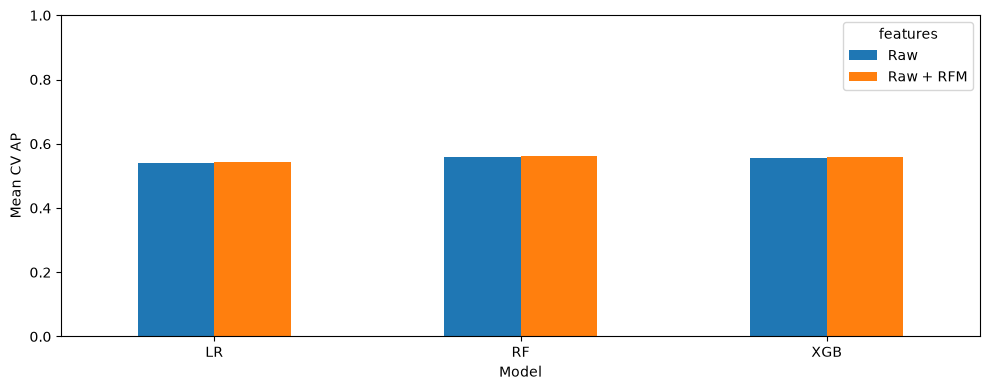

In [33]:
feature_result[['Raw', 'Raw + RFM']].plot.bar(rot=0)
plt.ylabel('Mean CV AP')
plt.xlabel('Model')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [34]:
best_name = cv_result.loc[0, 'model']
best_features = cv_result.loc[0, 'features']
best_cols = features[best_features]
best_search = searches[(best_features, best_name)]
best_params = best_search.best_params_
final_model = best_search.best_estimator_

best_features, best_name, best_params

('Raw + RFM', 'RF', {'model__max_depth': 12, 'model__min_samples_leaf': 5})

**Chọn ngưỡng:**
+ Dự đoán xác suất default trên 20% val.
+ Chọn ngưỡng có F1 cao nhất. Nếu bằng F1 thì lấy ngưỡng cao hơn.
+ Giữ nguyên model đã fit trên train, không fit thêm trên val.
+ F1 là tiêu chí thử nghiệm khi chưa xác định chi phí bỏ sót và cảnh báo nhầm.

In [35]:
val_proba = final_model.predict_proba(X_val[best_cols])[:, 1]
precision, recall, thresholds = precision_recall_curve(y_val, val_proba)

# Giá trị cuối của precision và recall không có ngưỡng tương ứng
val_f1 = np.divide(
    2 * precision[:-1] * recall[:-1],
    precision[:-1] + recall[:-1],
    out=np.zeros_like(thresholds),
    where=(precision[:-1] + recall[:-1]) > 0
)

threshold_result = pd.DataFrame({
    'threshold': thresholds,
    'precision': precision[:-1],
    'recall': recall[:-1],
    'F1': val_f1
})
threshold_result = threshold_result.sort_values(
    ['F1', 'threshold'], ascending=[False, False]
).reset_index(drop=True)

best_threshold = float(threshold_result.loc[0, 'threshold'])
threshold_result.head()

,threshold,precision,recall,F1
0,0.264146,0.516578,0.587481,0.549753
1,0.262464,0.515172,0.588989,0.549613
2,0.264070,0.516236,0.587481,0.549559
3,0.264353,0.516600,0.586727,0.549435
4,0.262394,0.514832,0.588989,0.549420


**Đánh giá:**
+ Dùng 20% test để đánh giá model và ngưỡng đã chọn.
+ So sánh ngưỡng 0.5 với ngưỡng chọn từ val, không chọn lại bằng test.
+ AP và ROC-AUC dùng xác suất. Accuracy, precision, recall và F1 dùng nhãn dự đoán.

In [36]:
test_proba = final_model.predict_proba(X_test[best_cols])[:, 1]
results = []

for threshold in [0.5, best_threshold]:
    test_pred = (test_proba >= threshold).astype(int)
    results.append({
        'threshold': threshold,
        'AP': average_precision_score(y_test, test_proba),
        'ROC_AUC': roc_auc_score(y_test, test_proba),
        'accuracy': accuracy_score(y_test, test_pred),
        'precision': precision_score(y_test, test_pred, zero_division=0),
        'recall': recall_score(y_test, test_pred, zero_division=0),
        'F1': f1_score(y_test, test_pred, zero_division=0)
    })

test_result = pd.DataFrame(results)
test_result

,threshold,AP,ROC_AUC,accuracy,precision,recall,F1
0,0.500000,0.550759,0.771808,0.816619,0.659634,0.353695,0.460481
1,0.264146,0.550759,0.771808,0.778074,0.498672,0.566365,0.530367


In [37]:
test_pred = (test_proba >= best_threshold).astype(int)
report = classification_report(y_test, test_pred, output_dict=True, zero_division=0)

pd.DataFrame(report).T

,precision,recall,f1-score,support
0,0.871852,0.838226,0.854708,4667.000000
1,0.498672,0.566365,0.530367,1326.000000
accuracy,0.778074,0.778074,0.778074,0.778074
macro avg,0.685262,0.702295,0.692538,5993.000000
weighted avg,0.789283,0.778074,0.782945,5993.000000


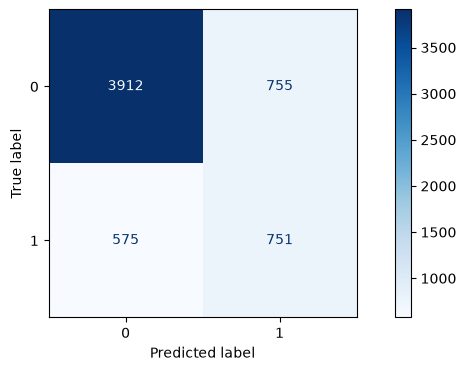

In [38]:
cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=[0, 1]).plot(cmap='Blues')
plt.show()